import libraries and dataset

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset

In [28]:
url = "https://raw.githubusercontent.com/utsav2110/IE494_BDP_Lab7/main/data/real_estate.csv"

df = pd.read_csv(url)

df.columns = [
    "No",
    "Transaction_Date",
    "House_Age",
    "MRT_Distance",
    "Convenience_Stores",
    "Latitude",
    "Longitude",
    "House_Price"
]

# 2. Display basic information

In [29]:
df.head()
df.tail()
df.shape
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   No                  414 non-null    int64  
 1   Transaction_Date    414 non-null    float64
 2   House_Age           414 non-null    float64
 3   MRT_Distance        414 non-null    float64
 4   Convenience_Stores  414 non-null    int64  
 5   Latitude            414 non-null    float64
 6   Longitude           414 non-null    float64
 7   House_Price         414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


np.int64(0)

**QUESTION  - WHAT ARE THE AVERAGE,MEDIAN,MINIMUM,MAXIMUM**

In [37]:
prices = df["House_Price"].to_numpy()

print("Average price:", np.mean(prices))
print("Median price:", np.median(prices))
print("Minimum price:", np.min(prices))
print("Maximum price:", np.max(prices))

Average price: 37.980193236714975
Median price: 38.45
Minimum price: 7.6
Maximum price: 117.5


**QUESTION 2 - WHAT IS THE AVERAGE HOUSE AGE **

In [31]:
print("Average House Age:", df["House_Age"].mean())

Average House Age: 17.71256038647343


**QUESTION  - COMPARE AVERAGE PRICE FOR PROPERTIES NAER AND FAR FROM THE MRT STATION USING A SIMPLE THRESHOLD CHOSEN BY YOUR TEAM**

In [32]:
df["MRT_Category"] = np.where(
    df["MRT_Distance"] <= 1000,
    "Near MRT",
    "Far from MRT"
)

df.groupby("MRT_Category")["House_Price"].mean()

,House_Price
MRT_Category,
Far from MRT,24.631159
Near MRT,44.654710


**QUESTION - DO RECORDS WITH MORE NEARBY CONVIENCE STORES SHOW A DIFFERENTAVERAGE**

In [42]:
print("\n========== CONVENIENCE STORE COUNTS ==========")

print(df["Convenience_Stores"].value_counts().sort_index())

print("\n========== AVERAGE PRICE BY STORES ==========")

store_analysis = df.groupby("Convenience_Stores")["House_Price"].agg(
    ["count", "mean", "median"]
)
print(store_analysis)


========== CONVENIENCE STORE COUNTS ==========
Convenience_Stores
0     67
1     46
2     24
3     46
4     31
5     67
6     37
7     31
8     30
9     25
10    10
Name: count, dtype: int64

========== AVERAGE PRICE BY STORES ==========
                    count       mean  median
Convenience_Stores                          
0                      67  26.462687   22.30
1                      46  31.839130   28.70
2                      24  31.412500   30.65
3                      46  29.536957   28.25
4                      31  37.474194   37.40
5                      67  44.729851   44.50
6                      37  46.951351   45.70
7                      31  43.848387   42.00
8                      30  44.696667   42.75
9                      25  51.732000   50.80
10                     10  48.430000   47.55


**QUESTION  - FIND THE 10 HIGHEST-PRICED RECORDS**

In [39]:
df["Convenience_Stores"].value_counts().sort_index()
df.groupby("Convenience_Stores")["House_Price"].mean()
top10 = df.sort_values(
    by="House_Price",
    ascending=False
).head(10)

print(top10)

      No  Transaction_Date  House_Age  MRT_Distance  Convenience_Stores  \
270  271          2013.333       10.8     252.58220                   1   
220  221          2013.333       37.2     186.51010                   9   
312  313          2013.583       35.4     318.52920                   9   
166  167          2013.417        0.0     292.99780                   6   
105  106          2012.833        0.0     292.99780                   6   
16    17          2013.250        0.0     292.99780                   6   
379  380          2013.333        0.0     292.99780                   6   
389  390          2013.250       40.9     122.36190                   8   
413  414          2013.500        6.5      90.45606                   9   
258  259          2013.417        0.0     292.99780                   6   

     Latitude  Longitude  House_Price MRT_Category  
270  24.97460  121.53046        117.5     Near MRT  
220  24.97703  121.54265         78.3     Near MRT  
312  24.97071  

**QUESTION - CHECK FOR THE MISSSING VALUES AND DUBLICATES**

In [38]:
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())


========== MISSING VALUES ==========
No                    0
Transaction_Date      0
House_Age             0
MRT_Distance          0
Convenience_Stores    0
Latitude              0
Longitude             0
House_Price           0
MRT_Category          0
dtype: int64


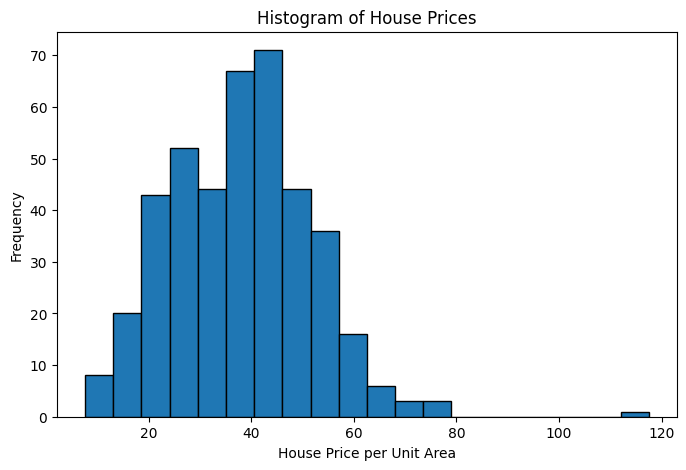

In [34]:
plt.figure(figsize=(8,5))

plt.hist(df["House_Price"], bins=20, edgecolor="black")

plt.title("Histogram of House Prices")
plt.xlabel("House Price per Unit Area")
plt.ylabel("Frequency")

plt.show()

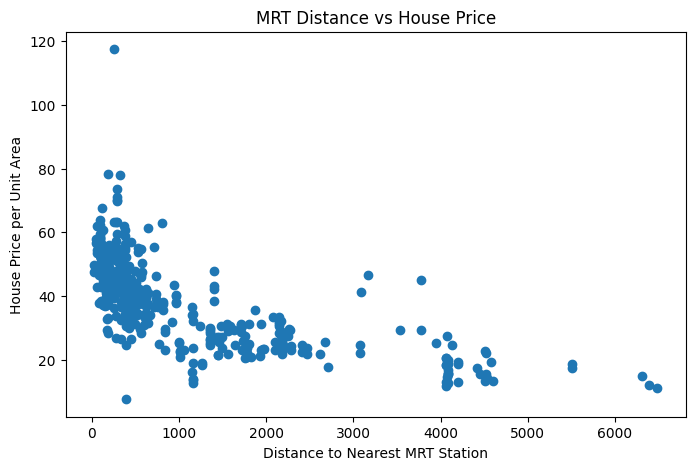

In [35]:
plt.figure(figsize=(8,5))

plt.scatter(df["MRT_Distance"], df["House_Price"])

plt.title("MRT Distance vs House Price")
plt.xlabel("Distance to Nearest MRT Station")
plt.ylabel("House Price per Unit Area")

plt.show()

In [36]:
print("1. House prices vary across the dataset.")

print("2. Average prices differ between properties near and far from MRT stations.")

print("3. Average prices vary across properties with different numbers of nearby convenience stores.")

1. House prices vary across the dataset.
2. Average prices differ between properties near and far from MRT stations.
3. Average prices vary across properties with different numbers of nearby convenience stores.
